In [3]:
import pandas as pd
import torch
import json
import matplotlib.pyplot as plt
import mindspore as ms
import numpy as np

from torch.nn.functional import cosine_similarity
from sklearn.metrics import roc_curve, auc

In [4]:
# do it at a complex level
rl_df = pd.read_csv("data/cellchatdb.csv")
rl_df = rl_df[['interaction_name_2', 'annotation']]
rl_df['is_multi_unit_complex'] = rl_df['interaction_name_2'].apply(lambda x: '+' in x)
rl_df = rl_df[rl_df['is_multi_unit_complex'] == False]


rl_df['partner_a'] = rl_df['interaction_name_2'].apply(lambda x: x.split(" - ")[0].replace("(", "").replace(")", ""))
rl_df['partner_b'] = rl_df['interaction_name_2'].apply(lambda x: x.split(" - ")[-1].replace("(", "").replace(")", ""))

rl_df['partner_a'] = rl_df['partner_a'].apply(lambda x: x.split('+'))
rl_df['partner_b'] = rl_df['partner_b'].apply(lambda x: x.split('+'))
rl_df['all_partners'] = rl_df.apply(lambda row: row['partner_a'] + row['partner_b'], axis=1)

In [ ]:
# ckpt_path = "/Users/maciejwiatrak/Downloads/best_12k_no_pseudobulk_no_gex.ckpt"
ckpt_path = "/Users/maciejwiatrak/Downloads/mct_checkpoint_12k.ckpt"


mct_embeddings = torch.load(
    ckpt_path, map_location="cpu", weights_only=False
)['state_dict']['model.gene_id_classifier.decoder.weight']  # extract gene embeddings from the classifier head weights

# load ENSEMBL ID to idx map
with open("data/gene_symbol2idx.json", "r") as f:
    gene_symbol2idx = json.load(f)

mct_gene_symbol2emb = {gene: mct_embeddings[idx] for gene, idx in gene_symbol2idx.items()}

In [5]:
## scGPT embedding weights
scgpt_weights = torch.load(
    "/Users/maciejwiatrak/Downloads/best_model_scgpt.pt", map_location="cpu"
)
gene_embeddings = scgpt_weights['encoder.embedding.weight']
# gene_info_scgpt = pd.read_csv(
#     "/Users/maciejwiatrak/Downloads/gene_info_scgpt.csv"
# )
# gene_info_scgpt
with open("/Users/maciejwiatrak/Downloads/scgpt_gene_symbol2idx.json", "r") as f:
    scgpt_gene_symbol2idx = json.load(f)

scgpt_gene_symbol2emb = {gene: gene_embeddings[idx] for gene, idx in scgpt_gene_symbol2idx.items()}

## scPRINT embedding weights
gene_embeddings = pd.read_parquet(
    "/Users/maciejwiatrak/Downloads/scprint_gene_embeddings.parquet"
)
# subset to genes present in scGPT
scgpt_gene_info = pd.read_csv(
    "/Users/maciejwiatrak/Downloads/gene_info_scgpt.csv"
)
ensembleid2symbol = {row['feature_id']: row['feature_name'] for _, row in scgpt_gene_info.iterrows()}
gene_embeddings = gene_embeddings[gene_embeddings.index.isin(ensembleid2symbol.keys())]
scprint_gene_symbol2emb = {ensembleid2symbol[gene]: torch.tensor(gene_embeddings.loc[gene].values) for gene in gene_embeddings.index}

# CellPLM gene embeddings
cellplm_weights = torch.load(
    "/Users/maciejwiatrak/Downloads/20230926_85M.best.ckpt", map_location="cpu"
)
gene_embeddings = cellplm_weights['model_state_dict']['embedder.feat_enc.emb']
with open("/Users/maciejwiatrak/Downloads/20230926_85M.config.json", "r") as f:
    cellplm_gene_list = json.load(f)['gene_list']
cellplm_genesymbol2idx = {ensembleid2symbol[gene]: idx for idx, gene in enumerate(cellplm_gene_list) if gene in ensembleid2symbol}
cellplm_gene_symbol2emb = {gene: gene_embeddings[idx] for gene, idx in cellplm_genesymbol2idx.items()}

# CellFM gene embeddings
gene_embeddings = ms.load_checkpoint("/Users/maciejwiatrak/Downloads/CellFM_80M_weight.ckpt")['gene_emb'].value()
gene_embeddings = torch.tensor(np.array(gene_embeddings))
genemap = pd.read_csv("/Users/maciejwiatrak/Downloads/genemap.csv")
cfm_gene_symbol2emb = {row['Unnamed: 0']: gene_embeddings[row['idx']] for _, row in genemap.iterrows()}

# scFoundation gene embeddings
scf_gene_symbol2idx = pd.read_csv("/Users/maciejwiatrak/Downloads/OS_scRNA_gene_index.19264.tsv", sep="\t")
gene_name2idx = {row['gene_name']: row['index'] for _, row in scf_gene_symbol2idx.iterrows()}
weights = torch.load(
    "/Users/maciejwiatrak/Downloads/models.ckpt", map_location="cpu"
)['gene']['state_dict']['model.pos_emb.weight']
scf_gene_symbol2emb = {gene: weights[idx] for gene, idx in gene_name2idx.items()}

# esm2 embedding
esm2_embeddings = pd.read_parquet("/Users/maciejwiatrak/Downloads/esm2_650m_human_proteome_embeds.parquet")
esm2_gene_symbol2emb = {row['gene_name']: torch.tensor(row['esm2_embedding']) for _, row in esm2_embeddings.iterrows()}

/var/folders/03/cqvkxcyx19g01v4r4gc8r8dr0000gn/T/ipykernel_69572/1658116122.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  scgpt_weights = torch.load(
/var/folders/03/c

In [6]:
## Get an intersection of genes present in all models
common_genes = set(mct_gene_symbol2emb.keys()) & set(scgpt_gene_symbol2emb.keys()) & set(scf_gene_symbol2emb.keys()) & set(scprint_gene_symbol2emb.keys()) & set(cellplm_gene_symbol2emb.keys()) & set(cfm_gene_symbol2emb.keys()) & set(esm2_gene_symbol2emb.keys())
print(f"Number of common genes across all models: {len(common_genes)}")

# filter gene embeddings to only include common genes
mct_gene_symbol2emb = {gene: emb for gene, emb in mct_gene_symbol2emb.items() if gene in common_genes}
scgpt_gene_symbol2emb = {gene: emb for gene, emb in scgpt_gene_symbol2emb.items() if gene in common_genes}
scprint_gene_symbol2emb = {gene: emb for gene, emb in scprint_gene_symbol2emb.items() if gene in common_genes}
scf_gene_symbol2emb = {gene: emb for gene, emb in scf_gene_symbol2emb.items() if gene in common_genes}
cellplm_gene_symbol2emb = {gene: emb for gene, emb in cellplm_gene_symbol2emb.items() if gene in common_genes}
cfm_gene_symbol2emb = {gene: emb for gene, emb in cfm_gene_symbol2emb.items() if gene in common_genes}
esm2_gene_symbol2emb = {gene: emb for gene, emb in esm2_gene_symbol2emb.items() if gene in common_genes}
assert len(mct_gene_symbol2emb) == len(scgpt_gene_symbol2emb) == len(scf_gene_symbol2emb) == len(scprint_gene_symbol2emb) == len(cellplm_gene_symbol2emb) == len(cfm_gene_symbol2emb) == len(esm2_gene_symbol2emb)

Number of common genes across all models: 18835


In [7]:
from tqdm import tqdm


def sample_negatives(positives_df: pd.DataFrame, potential_genes: set, num_negative_per_positive=2, seed=1):
    """Sample negative interactions from single genes. Converts list-type partners to sorted tuples for set operations."""
    np.random.seed(seed)
    positives_df = positives_df.copy()
    positives_df['seed'] = seed
    negative_samples = []
    n_negatives_per_item = num_negative_per_positive // 2
    for _, row in tqdm(positives_df.iterrows()):
        # Convert lists to tuples for set operations
        partner_a = tuple(sorted(row['partner_a'])) if isinstance(row['partner_a'], list) else row['partner_a']
        partner_b = tuple(sorted(row['partner_b'])) if isinstance(row['partner_b'], list) else row['partner_b']
        
        # sample n_negatives_per_item negative ligands for each positive receptor
        negative_ligands = np.random.choice(list(potential_genes - {partner_a}), size=n_negatives_per_item, replace=False)
        for neg_ligand in negative_ligands:
            negative_samples.append({'partner_a': neg_ligand, 'partner_b': partner_b, 'annotation': row['annotation'], 'label': 0, 'seed': seed})
        # sample n_negatives_per_item negative receptors for each positive ligand
        negative_receptors = np.random.choice(list(potential_genes - {partner_b}), size=n_negatives_per_item, replace=False)
        for neg_receptor in negative_receptors:
            negative_samples.append({'partner_a': partner_a, 'partner_b': neg_receptor, 'annotation': row['annotation'], 'label': 0, 'seed': seed})
    negative_df = pd.DataFrame(negative_samples)
    df = pd.concat([positives_df, negative_df], ignore_index=True)
    # Normalize gene_pair format
    df['gene_pair'] = df.apply(lambda row: "_".join(sorted([str(row['partner_a']), str(row['partner_b'])])), axis=1)
    # Preserve seed information during deduplication
    df = df.drop_duplicates(subset=['gene_pair', 'seed'], keep='first')
    return df


def sample_negatives_w_complexes(positives_df: pd.DataFrame, potential_genes: set, num_negative_per_positive=2, seed=1):
    """
    Sample negative interactions accounting for multi-gene complexes.
    
    For each positive interaction:
    - For partner_a (receptor): sample negative complexes by replacing each gene in the complex
      with a random gene from potential_genes (ensuring no duplicates within a complex)
    - For partner_b (ligand): apply the same strategy
    - Each replacement operation generates one negative sample

    Args:
        positives_df: DataFrame with 'partner_a', 'partner_b', 'directionality', 'label' columns
        potential_genes: set of all available genes
        num_negative_per_positive: target number of negative samples per positive
        seed: random seed for reproducibility

    Returns:
        DataFrame with positive and negative samples, deduplicated by gene_pair and seed
    """
    np.random.seed(seed)
    positives_df = positives_df.copy()
    positives_df['seed'] = seed
    negative_samples = []

    for _, row in tqdm(positives_df.iterrows()):
        partner_a = row['partner_a']  # list of genes
        partner_b = row['partner_b']  # list of genes

        # Strategy 1: Replace each gene in partner_a (receptor complex) with a random gene
        # Sample up to (num_negative_per_positive // 2) negatives by varying partner_a
        n_negatives_a = min(len(partner_a), num_negative_per_positive // 2)
        if n_negatives_a > 0 and len(partner_a) > 0:
            genes_to_replace_in_a = np.random.choice(len(partner_a), size=min(n_negatives_a, len(partner_a)), replace=False)

            for idx_to_replace in genes_to_replace_in_a:
                # Get genes not in partner_b to avoid creating duplicates
                excluded_genes = set(partner_b) | {partner_a[idx_to_replace]}
                available_genes = list(potential_genes - excluded_genes)

                if available_genes:
                    replacement_gene = np.random.choice(available_genes)
                    new_partner_a = partner_a.copy()
                    new_partner_a[idx_to_replace] = replacement_gene
                    negative_samples.append({
                        'partner_a': new_partner_a,
                        'partner_b': partner_b,
                        'annotation': row['annotation'],
                        'label': 0,
                        'seed': seed
                    })

        # Strategy 2: Replace each gene in partner_b (ligand complex) with a random gene
        # Sample up to (num_negative_per_positive // 2) negatives by varying partner_b
        n_negatives_b = min(len(partner_b), num_negative_per_positive // 2)
        if n_negatives_b > 0 and len(partner_b) > 0:
            genes_to_replace_in_b = np.random.choice(len(partner_b), size=min(n_negatives_b, len(partner_b)), replace=False)

            for idx_to_replace in genes_to_replace_in_b:
                # Get genes not in partner_a to avoid creating duplicates
                excluded_genes = set(partner_a) | {partner_b[idx_to_replace]}
                available_genes = list(potential_genes - excluded_genes)

                if available_genes:
                    replacement_gene = np.random.choice(available_genes)
                    new_partner_b = partner_b.copy()
                    new_partner_b[idx_to_replace] = replacement_gene
                    negative_samples.append({
                        'partner_a': partner_a,
                        'partner_b': new_partner_b,
                        'annotation': row['annotation'],
                        'label': 0,
                        'seed': seed
                    })

    # Convert lists to tuples for consistent deduplication
    negative_df = pd.DataFrame(negative_samples)
    if len(negative_df) > 0:
        negative_df['gene_pair'] = negative_df.apply(
            lambda row: "_".join(sorted(
                ["_".join(row['partner_a']), "_".join(row['partner_b'])]
            )),
            axis=1
        )
    else:
        # Handle empty negative_df case
        negative_df['gene_pair'] = []

    # Combine positives and negatives
    positives_df['gene_pair'] = positives_df.apply(
        lambda row: "_".join(sorted(
            ["_".join(row['partner_a']), "_".join(row['partner_b'])]
        )),
        axis=1
    )

    df = pd.concat([positives_df, negative_df], ignore_index=True)

    # Deduplicate by gene_pair and seed (preserve seed information)
    df = df.drop_duplicates(subset=['gene_pair', 'seed'], keep='first')

    return df


rl_df_w_negs = []
rl_df['label'] = 1
# Using 5 seeds for robust evaluation; provides better mean and std estimates across runs
for seed in range(3):
    # rl_df_w_negs.append(sample_negatives(rl_df[['partner_a', 'partner_b', 'directionality', 'label']].copy(), common_genes, num_negative_per_positive=2, seed=seed))
    rl_df_w_negs.append(sample_negatives_w_complexes(rl_df[['partner_a', 'partner_b', 'annotation', 'label']].copy(), common_genes, num_negative_per_positive=2, seed=seed))
rl_df_w_negs = pd.concat(rl_df_w_negs, ignore_index=True)
rl_df_w_negs.head()

845it [00:05, 159.17it/s]
845it [00:05, 149.86it/s]
845it [00:05, 153.70it/s]


,partner_a,partner_b,annotation,label,seed,gene_pair
0,[VSIR],[IGSF11],Cell-Cell Contact,1,0,IGSF11_VSIR
1,[EFNA5],[EPHA7],Cell-Cell Contact,1,0,EFNA5_EPHA7
2,[EFNA5],[EPHA8],Cell-Cell Contact,1,0,EFNA5_EPHA8
3,[EFNA5],[EPHB2],Cell-Cell Contact,1,0,EFNA5_EPHB2
4,[EFNB1],[EPHA4],Cell-Cell Contact,1,0,EFNB1_EPHA4


In [8]:
def compute_cosine_similarity_complexes(
    row: dict,
    gene_symbol2emb: dict,
):
    """Compute cosine similarity for complexes by averaging embeddings of constituent genes.
    
    Handles edge cases: empty gene lists, missing embeddings, single-gene complexes.
    """
    try:
        # Get embeddings for genes present in the embedding dictionary
        lig_genes = [gene_symbol2emb[item] for item in row['partner_a'] if item in gene_symbol2emb]
        rec_genes = [gene_symbol2emb[item] for item in row['partner_b'] if item in gene_symbol2emb]
        
        # Handle empty cases
        if len(lig_genes) == 0 or len(rec_genes) == 0:
            return None
        
        # Average embeddings; handles single-gene case automatically
        lig_emb = torch.stack(lig_genes).mean(dim=0)
        rec_emb = torch.stack(rec_genes).mean(dim=0)
        
        cs = cosine_similarity(lig_emb, rec_emb, dim=0).item()
        # Normalise the CS to be between 0 and 1
        return (cs + 1) / 2
    except Exception as e:
        print(f"Error computing cosine similarity for row {row}: {e}")
        return None


rl_df_w_negs['mct_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, mct_gene_symbol2emb), axis=1)
rl_df_w_negs['scgpt_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, scgpt_gene_symbol2emb), axis=1)
rl_df_w_negs['scprint_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, scprint_gene_symbol2emb), axis=1)
rl_df_w_negs['cellplm_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, cellplm_gene_symbol2emb), axis=1)
rl_df_w_negs['cfm_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, cfm_gene_symbol2emb), axis=1)
rl_df_w_negs['scf_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, scf_gene_symbol2emb), axis=1)
rl_df_w_negs['esm2_cs'] = rl_df_w_negs.apply(lambda row: compute_cosine_similarity_complexes(row, esm2_gene_symbol2emb), axis=1)

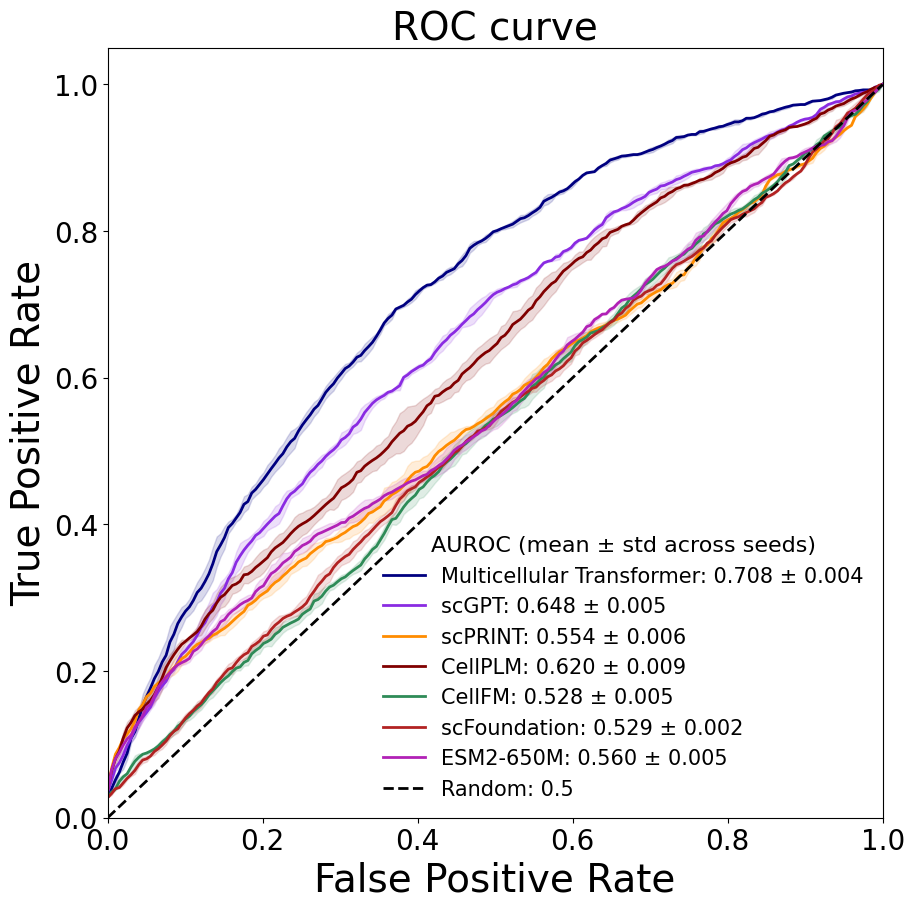

In [14]:
# Average ROC across seeds
fpr_grid = np.linspace(0.0, 1.0, 200)

models = {
    'Multicellular Transformer': ('mct_cs', '#000080'),
    'scGPT': ('scgpt_cs', '#8A2BE2'),
    'scPRINT': ('scprint_cs', '#FF8C00'),
    'CellPLM': ('cellplm_cs', '#800000'),
    'CellFM': ('cfm_cs', '#2E8B57'),
    'scFoundation': ('scf_cs', '#B22222'),
    # add ESM2
    'ESM2-650M': ('esm2_cs', "#B121B6"),
}

def mean_roc_across_seeds(df, score_col, seeds, fpr_grid):
    aucs = []
    tprs = []
    for seed in seeds:
        df_seed = df[df['seed'] == seed].dropna(subset=[score_col])
        if df_seed['label'].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(df_seed['label'], df_seed[score_col])
        aucs.append(auc(fpr, tpr))
        tprs.append(np.interp(fpr_grid, fpr, tpr))
    tprs = np.asarray(tprs)
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0)
    return mean_tpr, std_tpr, float(np.mean(aucs)), float(np.std(aucs))

seeds = sorted(rl_df_w_negs['seed'].unique())

plt.figure(figsize=(10, 10))
for name, (score_col, color) in models.items():
    mean_tpr, std_tpr, mean_auc, std_auc = mean_roc_across_seeds(rl_df_w_negs, score_col, seeds, fpr_grid)
    plt.plot(fpr_grid, mean_tpr, lw=2, color=color, label=f'{name}: {mean_auc:.3f} ± {std_auc:.3f}')
    plt.fill_between(fpr_grid, np.maximum(mean_tpr - std_tpr, 0), np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.15)

plt.plot([0, 1], [0, 1], color='black', linestyle='--', lw=2, label='Random: 0.5')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=28)
plt.ylabel('True Positive Rate', fontsize=28)
plt.title('ROC curve', fontsize=28)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(frameon=False, loc='lower right', fontsize=15, title='AUROC (mean ± std across seeds)', title_fontsize=16)
plt.show()

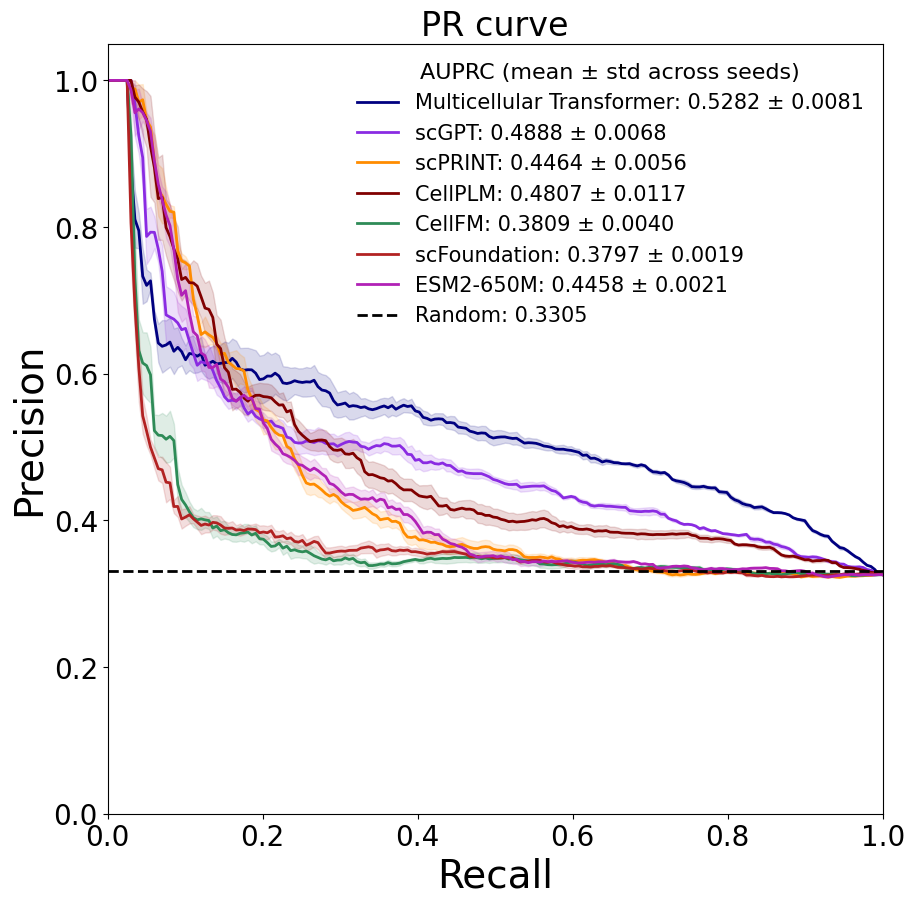

In [15]:
# TODO: Plot AUPRC across all pairs

from sklearn.metrics import average_precision_score, precision_recall_curve

recall_grid = np.linspace(0.0, 1.0, 200)

def mean_pr_across_seeds(df, score_col, seeds, recall_grid):
    aps = []
    precisions = []

    for seed in seeds:
        df_seed = df[df["seed"] == seed].dropna(subset=[score_col])
        if df_seed["label"].nunique() < 2:
            continue

        precision, recall, _ = precision_recall_curve(df_seed["label"], df_seed[score_col])
        ap = average_precision_score(df_seed["label"], df_seed[score_col])

        # sklearn returns recall in descending order; reverse for interpolation
        precision = precision[::-1]
        recall = recall[::-1]

        interp_precision = np.interp(recall_grid, recall, precision)
        precisions.append(interp_precision)
        aps.append(ap)

    precisions = np.asarray(precisions)
    mean_precision = precisions.mean(axis=0)
    std_precision = precisions.std(axis=0)

    return mean_precision, std_precision, float(np.mean(aps)), float(np.std(aps))

seeds = sorted(rl_df_w_negs["seed"].unique())

plt.figure(figsize=(10, 10))
for name, (score_col, color) in models.items():
    mean_precision, std_precision, mean_ap, std_ap = mean_pr_across_seeds(
        rl_df_w_negs, score_col, seeds, recall_grid
    )
    plt.plot(
        recall_grid,
        mean_precision,
        lw=2,
        color=color,
        label=f"{name}: {mean_ap:.4f} ± {std_ap:.4f}",
    )
    plt.fill_between(
        recall_grid,
        np.maximum(mean_precision - std_precision, 0),
        np.minimum(mean_precision + std_precision, 1),
        color=color,
        alpha=0.15,
    )

positive_rate = rl_df_w_negs["label"].mean()
plt.hlines(
    positive_rate,
    xmin=0,
    xmax=1,
    color="black",
    linestyle="--",
    lw=2,
    label=f"Random: {positive_rate:.4f}",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall", fontsize=28)
plt.ylabel("Precision", fontsize=28)
plt.title("PR curve", fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(frameon=False, loc="upper right", fontsize=15, title="AUPRC (mean ± std across seeds)", title_fontsize=16)
plt.show()


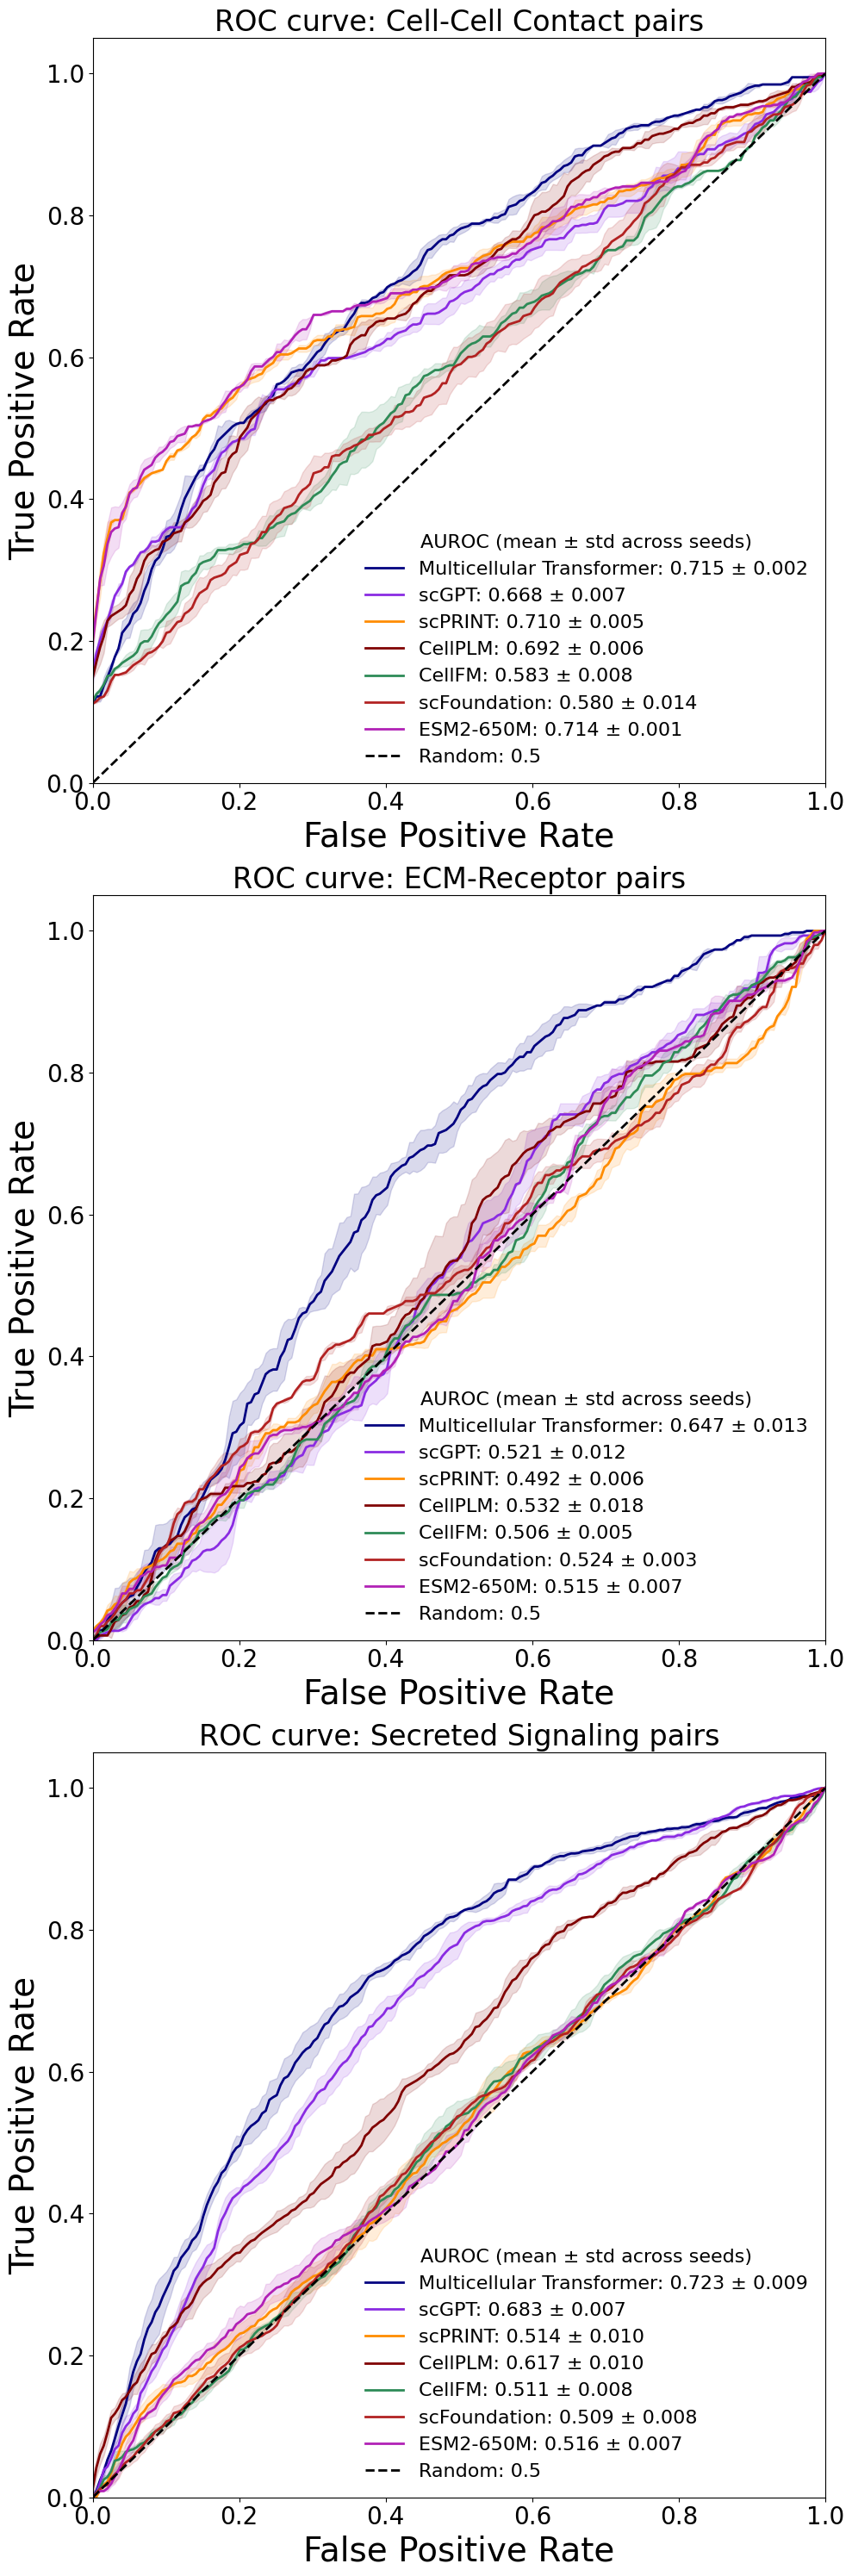

In [16]:
annotations = sorted(rl_df_w_negs["annotation"].dropna().unique())
fig, axes = plt.subplots(len(annotations), 1, figsize=(10, 10 * len(annotations)), dpi=100)

if len(annotations) == 1:
    axes = [axes]

for ax, annotation in zip(axes, annotations):
    df_dir = rl_df_w_negs[rl_df_w_negs["annotation"] == annotation].copy()
    seeds_dir = sorted(df_dir["seed"].unique())

    for name, (score_col, color) in models.items():
        mean_tpr, std_tpr, mean_auc, std_auc = mean_roc_across_seeds(
            df_dir, score_col, seeds_dir, fpr_grid
        )
        ax.plot(
            fpr_grid,
            mean_tpr,
            lw=2,
            color=color,
            label=f"{name}: {mean_auc:.3f} ± {std_auc:.3f}",
        )
        ax.fill_between(
            fpr_grid,
            np.maximum(mean_tpr - std_tpr, 0),
            np.minimum(mean_tpr + std_tpr, 1),
            color=color,
            alpha=0.15,
        )

    ax.plot([0, 1], [0, 1], color="black", linestyle="--", lw=2, label="Random: 0.5")
    ax.set_title(f"ROC curve: {annotation} pairs", fontsize=24)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate", fontsize=28)
    ax.set_ylabel("True Positive Rate", fontsize=28)
    ax.tick_params(axis="both", labelsize=20)
    ax.legend(frameon=False, loc="lower right", fontsize=16, title="AUROC (mean ± std across seeds)", title_fontsize=16)

plt.tight_layout()
plt.show()

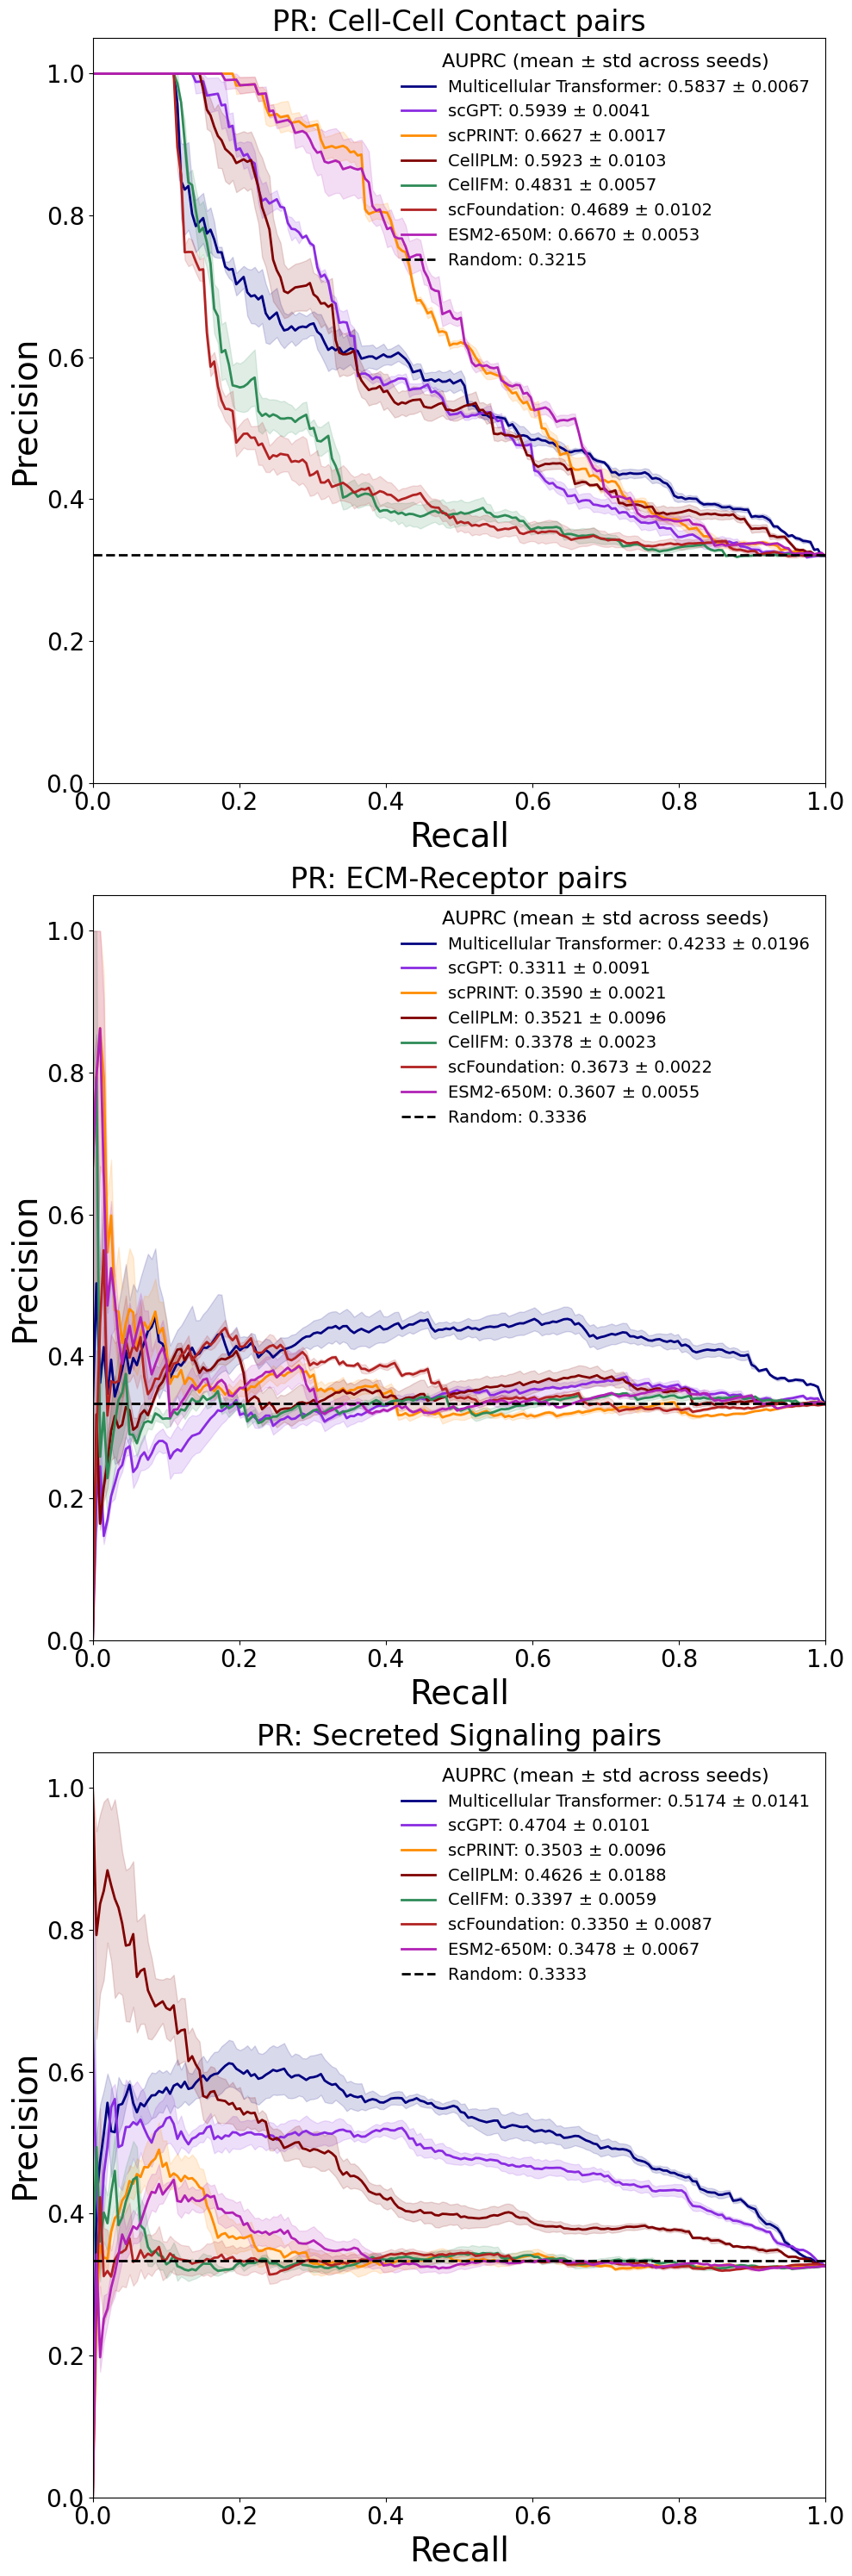

In [17]:
# TODO: Plot AUPRC separately for each directionality (one below another)

annotations = sorted(rl_df_w_negs["annotation"].dropna().unique())
fig, axes = plt.subplots(len(annotations), 1, figsize=(10, 10 * len(annotations)), dpi=100)

if len(annotations) == 1:
    axes = [axes]

for ax, annotation in zip(axes, annotations):
    df_dir = rl_df_w_negs[rl_df_w_negs["annotation"] == annotation].copy()
    seeds_dir = sorted(df_dir["seed"].unique())
    positive_rate = df_dir["label"].mean()

    for name, (score_col, color) in models.items():
        mean_precision, std_precision, mean_ap, std_ap = mean_pr_across_seeds(
            df_dir, score_col, seeds_dir, recall_grid
        )
        ax.plot(
            recall_grid,
            mean_precision,
            lw=2,
            color=color,
            label=f"{name}: {mean_ap:.4f} ± {std_ap:.4f}",
        )
        ax.fill_between(
            recall_grid,
            np.maximum(mean_precision - std_precision, 0),
            np.minimum(mean_precision + std_precision, 1),
            color=color,
            alpha=0.15,
        )

    ax.hlines(
        positive_rate,
        xmin=0,
        xmax=1,
        color="black",
        linestyle="--",
        lw=2,
        label=f"Random: {positive_rate:.4f}",
    )
    ax.set_title(f"PR: {annotation} pairs", fontsize=24)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("Recall", fontsize=28)
    ax.set_ylabel("Precision", fontsize=28)
    ax.tick_params(axis="both", labelsize=20)
    ax.legend(frameon=False, loc="upper right", fontsize=14, title="AUPRC (mean ± std across seeds)", title_fontsize=16)

plt.tight_layout()
plt.show()

In [22]:
rl_df = pd.read_csv("data/receptor_ligand_liana_consensus.csv")
rl_df

,ligand,receptor,source,gene_pair,ligand_ensemblid,receptor_ensemblid,ensemblid_pair,ligand_uniprotid,receptor_uniprotid,ensemblid_unknown
0,LGALS9,PTPRC,liana_consensus,LGALS9_PTPRC,ENSG00000168961,ENSG00000081237,ENSG00000081237_ENSG00000168961,O00182,P08575,False
1,LGALS9,MET,liana_consensus,LGALS9_MET,ENSG00000168961,ENSG00000105976,ENSG00000105976_ENSG00000168961,O00182,NaN,False
2,LGALS9,CD44,liana_consensus,CD44_LGALS9,ENSG00000168961,ENSG00000026508,ENSG00000026508_ENSG00000168961,O00182,P16070,False
3,LGALS9,LRP1,liana_consensus,LGALS9_LRP1,ENSG00000168961,ENSG00000123384,ENSG00000123384_ENSG00000168961,O00182,Q07954,False
4,LGALS9,CD47,liana_consensus,CD47_LGALS9,ENSG00000168961,ENSG00000196776,ENSG00000168961_ENSG00000196776,O00182,Q08722,False
...,...,...,...,...,...,...,...,...,...,...
4619,BMP2,ACTR2,liana_consensus,ACTR2_BMP2,ENSG00000125845,ENSG00000138071,ENSG00000125845_ENSG00000138071,P12643,P61160,False
4620,BMP15,ACTR2,liana_consensus,ACTR2_BMP15,ENSG00000130385,ENSG00000138071,ENSG00000130385_ENSG00000138071,O95972,P61160,False
4621,CSF1,CSF3R,liana_consensus,CSF1_CSF3R,ENSG00000184371,ENSG00000119535,ENSG00000119535_ENSG00000184371,P09603,Q99062,False
4622,IL36G,IFNAR1,liana_consensus,IFNAR1_IL36G,ENSG00000136688,ENSG00000142166,ENSG00000136688_ENSG00000142166,Q9NZH8,P17181,False


In [23]:
import liana as li
import omnipath as op
import decoupler as dc

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/maciejwiatrak/miniconda3/envs/bacformer-release/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [71]:
from sklearn.metrics import roc_auc_score, average_precision_score

ccdb = li.rs.select_resource('cellchatdb')
receptors = ccdb.receptor.unique()
rl_df_w_negs['receptor'] = rl_df_w_negs.partner_b.apply(lambda x: x[0])
rl_rec_df = rl_df_w_negs[rl_df_w_negs.receptor.isin(receptors)]

rl_rec_df = rl_rec_df.dropna(subset=['mct_cs', 'scgpt_cs', 'scprint_cs', 'cellplm_cs', 'cfm_cs', 'scf_cs', 'esm2_cs'])

rl_rec_df = rl_rec_df.groupby(['receptor', 'seed'])[['label', 'mct_cs', 'scgpt_cs', 'scprint_cs', 'cellplm_cs', 'cfm_cs', 'scf_cs', 'esm2_cs']].agg(list).reset_index()
rl_rec_df['n_pos'] = rl_rec_df['label'].apply(lambda x: sum(x))
rl_rec_df['n_neg'] = rl_rec_df['label'].apply(lambda x: len(x) - sum(x))

rl_rec_df = rl_rec_df[rl_rec_df['n_pos'] > 0]  # filter out receptors with no positives
rl_rec_df = rl_rec_df[rl_rec_df['n_neg'] > 0]  # filter out receptors with no negatives

rl_rec_df['auroc_mct'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['mct_cs']), axis=1)
rl_rec_df['auprc_mct'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['mct_cs']), axis=1)
rl_rec_df['auroc_scgpt'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['scgpt_cs']), axis=1)
rl_rec_df['auprc_scgpt'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['scgpt_cs']), axis=1)
rl_rec_df['auroc_scprint'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['scprint_cs']), axis=1)
rl_rec_df['auprc_scprint'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['scprint_cs']), axis=1)
rl_rec_df['auroc_cellplm'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['cellplm_cs']), axis=1)
rl_rec_df['auprc_cellplm'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['cellplm_cs']), axis=1)
rl_rec_df['auroc_cfm'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['cfm_cs']), axis=1)
rl_rec_df['auprc_cfm'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['cfm_cs']), axis=1)
rl_rec_df['auroc_scf'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['scf_cs']), axis=1)
rl_rec_df['auprc_scf'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['scf_cs']), axis=1)
rl_rec_df['auroc_esm2'] = rl_rec_df.apply(lambda row: roc_auc_score(row['label'], row['esm2_cs']), axis=1)
rl_rec_df['auprc_esm2'] = rl_rec_df.apply(lambda row: average_precision_score(row['label'], row['esm2_cs']), axis=1)


In [77]:
auroc_df = rl_rec_df.melt(id_vars=['receptor', 'seed'], value_vars=['auroc_mct', 'auroc_scgpt', 'auroc_scprint', 'auroc_cellplm', 'auroc_cfm', 'auroc_scf', 'auroc_esm2'], var_name='model', value_name='auroc')
auprc_df = rl_rec_df.melt(id_vars=['receptor', 'seed'], value_vars=['auprc_mct', 'auprc_scgpt', 'auprc_scprint', 'auprc_cellplm', 'auprc_cfm', 'auprc_scf', 'auprc_esm2'], var_name='model', value_name='auprc')

/var/folders/03/cqvkxcyx19g01v4r4gc8r8dr0000gn/T/ipykernel_69572/1897912387.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



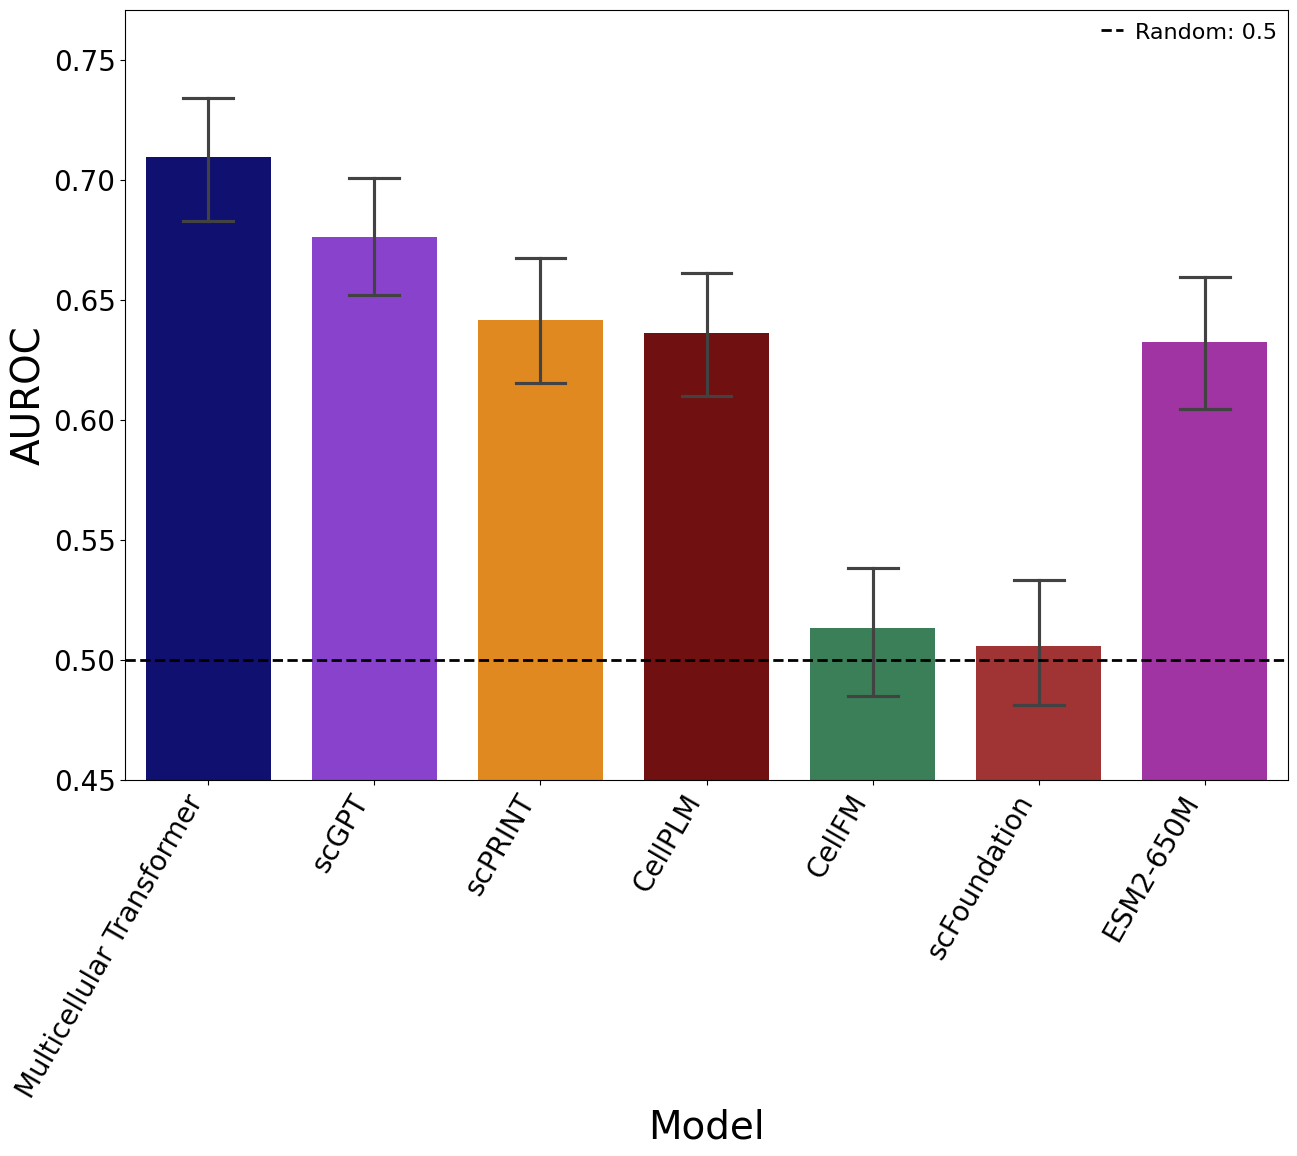

In [104]:
import seaborn as sns

models = {
    'Multicellular Transformer': ('auroc_mct', '#000080'),
    'scGPT': ('auroc_scgpt', '#8A2BE2'),
    'scPRINT': ('auroc_scprint', '#FF8C00'),
    'CellPLM': ('auroc_cellplm', '#800000'),
    'CellFM': ('auroc_cfm', '#2E8B57'),
    'scFoundation': ('auroc_scf', '#B22222'),
    # add ESM2
    'ESM2-650M': ('auroc_esm2', "#B121B6"),
}

# Plot AUROC box plot across models
plt.figure(figsize=(15, 10), dpi=100)
sns.barplot(
    data=auroc_df,
    x='model',
    y='auroc', 
    palette=[color for _, color in models.values()],
    width=0.75,
    capsize=0.3,
)

# Add random baseline
plt.axhline(y=0.5, color='black', linestyle='--', lw=2, label='Random: 0.5')

plt.ylim(0.45)
plt.yticks(fontsize=20)
plt.xticks(ticks=range(len(models)), labels=[name for name in models.keys()], rotation=60, ha='right', fontsize=20)
plt.xlabel("Model", fontsize=28)
plt.ylabel("AUROC", fontsize=28)
plt.legend(fontsize=16)
plt.show()


/var/folders/03/cqvkxcyx19g01v4r4gc8r8dr0000gn/T/ipykernel_69572/1078559405.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/var/folders/03/cqvkxcyx19g01v4r4gc8r8dr0000gn/T/ipykernel_69572/1078559405.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


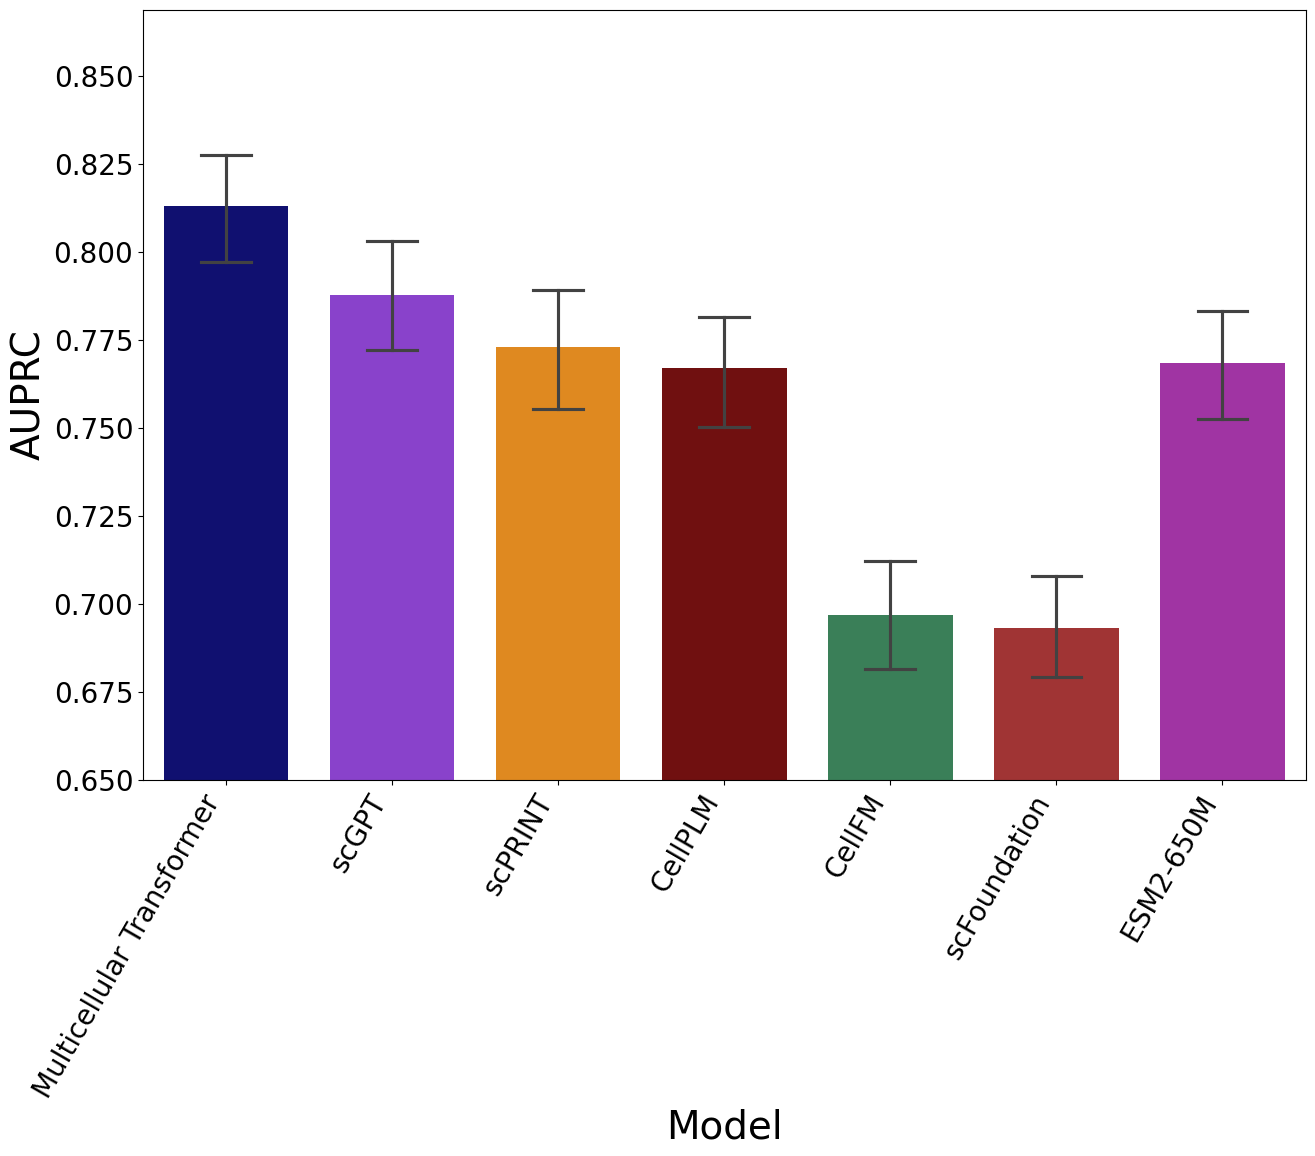

In [110]:
plt.figure(figsize=(15, 10), dpi=100)
sns.barplot(
    data=auprc_df,
    x='model',
    y='auprc', 
    palette=[color for _, color in models.values()],
    width=0.75,
    capsize=0.3,
)

# Add random baseline
# positive_rate = rl_rec_df['label'].apply(lambda x: sum(x) / len(x)).mean()
# plt.axhline(y=positive_rate, color='black', linestyle='--', lw=2, label=f'Random: {positive_rate:.4f}')

plt.ylim(0.65)
plt.yticks(fontsize=20)
plt.xticks(ticks=range(len(models)), labels=[name for name in models.keys()], rotation=60, ha='right', fontsize=20)
plt.xlabel("Model", fontsize=28)
plt.ylabel("AUPRC", fontsize=28)
plt.legend(fontsize=16)
plt.show()
